# Histogram analysis — Asimov vs median of toys

**Question.** Does the Asimov dataset predict the median result of an ensemble of toy
pseudo-experiments for the binned $m_{4\ell}$ analysis of off-shell $gg \to H^* \to ZZ \to 4\ell$?
This notebook is the histogram half of the reproduction; `nsbi_reproduction.ipynb` is the NSBI half.

**How it is organised.** §1 defines the model, the toys and the test statistic. §2 derives, from
first principles and in three steps, the statement that is actually being tested — the phrase
"Asimov equals the median of toys" is a shorthand that is false if read literally, and §2 sets out
what replaces it. §3 checks each of the three steps separately against the toys, so that a later
disagreement can be attributed to a specific assumption. §4 verifies the comparison code on ideal
likelihoods where the three steps hold by construction, §5 to §7 present the measurement, and §8
follows the two assumptions that can be reduced to a single number across luminosity. §9 to §11
hold a comparison with the original plots, the errata found while redoing the analysis, and the
commands needed to regenerate everything.

**Provenance.** All likelihood scans are computed by `../scripts/asimov_scan.py` (one shared
implementation for both notebooks) and stored under `../output/asimov_scan/hist/`; this notebook
only loads, summarises and plots them. Configuration: 300 000 events from the SBI sample,
2000 toys per luminosity point (each toy from its own random stream, master seed 42),
signal-strength grid $\mu \in [0, 4]$ with 161 points, luminosities
$\{1, 10, 30, 100, 140, 200, 300, 500, 700, 1000, 3000\}$ fb$^{-1}$.

**Writing rule.** Every quantity is defined before it is used, in standard statistics terms, and
every constant is computed rather than quoted. "CCGV" refers to Cowan, Cranmer, Gross and Vitells,
*Eur. Phys. J. C* 71 (2011) 1554, arXiv:1007.1727, which is the source of the asymptotic results
derived in §2.

## 1. Definitions

**Model.** The expected $m_{4\ell}$ histogram has 10 logarithmic bins in $[180, 1000]$ GeV. Its
content in bin $b$ is $\nu_b(\mu) \cdot L$, where $L$ is the integrated luminosity in fb$^{-1}$ and
$\nu_b(\mu)$ is the sum, over the events in bin $b$, of the per-event weights reweighted to signal
strength $\mu$ using the stored matrix elements
($w_i(\mu) = w_i \, [\mu\,\mathrm{msq}_{\rm sig} + \sqrt{\mu}\,\mathrm{msq}_{\rm int} + \mathrm{msq}_{\rm bkg}]_i / \mathrm{msq}_{{\rm sbi},i}$).
The likelihood is a product of independent Poisson probabilities over the 10 bins.

**Toys.** One toy pseudo-experiment fluctuates every event weight independently:
$k_i \sim \mathrm{Poisson}(w_i \cdot L)$, generated at $\mu_{\rm true} = 1$; the toy's histogram
is the sum of the $k_i$ in each bin. Each of the 2000 toys uses its own random stream.

**The Asimov dataset** is the histogram whose bin contents equal their expected values exactly:
$n_b = \nu_b(1) \cdot L$. It is the "no-fluctuation" dataset, and its two defining properties are
used repeatedly below: its best fit is exactly $\mu_{\rm true}$, and its curvature is the
*expected* rather than a fluctuating measure of how much the data constrain $\mu$.

**The test statistic.** For any dataset (toy or Asimov), we scan $-2 \ln L(\mu)$ over the grid and
define
$$t(\mu) \;=\; -2\left[\ln L(\mu) - \ln L(\hat\mu)\right],$$
where $\hat\mu$ is the position of that dataset's likelihood maximum on the grid, restricted to
$\mu \ge 0$. By construction $t \ge 0$ and $t(\hat\mu) = 0$. We write $t_A(\mu)$ for the Asimov
dataset's curve, and $\sigma$ for the standard deviation of $\hat\mu$ over repeated experiments.

**Stated limitations.** The prediction derived in §2 assumes that $\hat\mu$ can move freely, while
the scan is restricted to the window $\mu \in [0, 4]$; toys whose best fit is pushed against either
end are outside the scope of that derivation, and the fraction sitting at each end is reported
alongside every comparison. In addition, $\hat\mu$ is a grid minimum, so it is quantised in steps
of $0.025$; the resulting bias on $t$ is of order $(0.0125/\sigma)^2$ and is negligible at every
luminosity considered here.

In [11]:
import os, sys, json
import numpy as np
import torch
import matplotlib.pyplot as plt

PINK = '#AD1A72'    # SBI_shortcomings slide accent -- measured/toy quantities
PURPLE = '#7B2CBF'  # Asimov curve

# locate the container root both from notebooks/ (interactive) and elsewhere (headless)
ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if not os.path.isdir(os.path.join(ROOT, 'scripts')):
    ROOT = os.getcwd()
sys.path.insert(0, os.path.join(ROOT, 'scripts'))
from asimov_scan import (t_curves, crossing_interval, toy_quantiles, predicted_quantiles,
                         bootstrap_quantile_width_ratio, ncx2_cdf, ncx2_quantile)

LUMIS = [1, 10, 30, 100, 140, 200, 300, 500, 700, 1000, 3000]
SCandir = os.path.join(ROOT, 'output/asimov_scan/hist')
scans = {}
for L in LUMIS:
    d = os.path.join(SCandir, f'lumi_{L}')
    scans[L] = dict(
        nll_asimov=torch.load(os.path.join(d, 'nll_asimov.pt'), map_location='cpu').numpy(),
        nll_toys=torch.load(os.path.join(d, 'nll_toys.pt'), map_location='cpu').numpy(),
        mu=torch.load(os.path.join(d, 'mu_scan.pt'), map_location='cpu').numpy())
mu = scans[LUMIS[0]]['mu']
with open(os.path.join(SCandir, f'lumi_{LUMIS[0]}', 'meta.json')) as f:
    meta = json.load(f)
I_MU1 = int(np.argmin(np.abs(mu - 1.0)))   # grid index of mu = 1 (exactly on the grid)
print(f"loaded {len(scans)} luminosities, {meta['n_toys']} toys each, "
      f"mu grid {meta['mu_grid']}, engine commit {(meta['container_repo'] or 'n/a')[:9]}")

loaded 11 luminosities, 2000 toys each, mu grid [0.0, 4.0, 161], engine commit n/a


## 2. Why the comparison is made against a noncentral $\chi^2$

The property this notebook tests is usually quoted as "the Asimov dataset predicts the median of
the toys". That phrasing is convenient but, taken literally, false, and the redo of 2026-07-16
found that two of the errata in §10 follow from taking it literally. This section therefore
derives the statement the notebook actually tests, in three steps, so that the rest of the
notebook can be read as a check of each step in turn rather than as an assertion.

Throughout, $\mu_{\rm true} = 1$ is the value at which the toys were generated, $\hat\mu$ is the
best fit of one toy, and $\sigma$ is the standard deviation of $\hat\mu$ across repeated
experiments. All three steps are approximations that become exact only as the sample grows, and
each can fail on its own.

### Step 1 — every likelihood curve is the same parabola, shifted

Expanding $-2\ln L(\mu)$ about its own minimum, the constant term is removed by the subtraction
that defines $t$, and the linear term vanishes because the expansion is taken at a minimum. What
survives is

$$t(\mu) \;=\; \frac{(\mu - \hat\mu)^2}{\sigma^2} \;+\; \mathcal{O}\!\left((\mu - \hat\mu)^3\right).$$

The coefficient $1/\sigma^2$ is half the second derivative of $-2\ln L$ at the minimum, a quantity
known as the **observed Fisher information**: a measure of how sharply the likelihood peaks and
therefore of how tightly the data constrain $\mu$. In the large-sample limit this curvature stops
fluctuating from one dataset to the next, so all toy curves share a single shape and differ only
in where their minimum sits. A whole likelihood scan is then compressed into two numbers, one of
which is the same for every toy.

### Step 2 — that minimum is Gaussian-distributed

A maximum-likelihood estimator is asymptotically Gaussian about the true value,

$$\hat\mu \;\sim\; \mathcal{N}(\mu_{\rm true},\ \sigma),$$

with the *same* $\sigma$ that appeared in step 1. That the two coincide is not a coincidence but
the content of the Fisher-information identity: the curvature of the likelihood is the inverse of
the variance of the estimator that likelihood produces. Step 1 concerns the shape of a single
curve; step 2 concerns how that curve is placed, and only together do they fix the distribution
of $t$.

### Step 3 — a squared Gaussian is a noncentral $\chi^2$

Fix $\mu$ and define $z = (\mu - \hat\mu)/\sigma$. By step 2, $z$ is Gaussian with unit width and
mean $(\mu - \mu_{\rm true})/\sigma$; by step 1, $t(\mu) = z^2$. The square of a unit-width
Gaussian with a non-zero mean is, by definition, a **noncentral $\chi^2$ variate with one degree
of freedom**, whose noncentrality parameter is the squared mean,

$$\Lambda \;=\; \left(\frac{\mu - \mu_{\rm true}}{\sigma}\right)^{\!2}.$$

The name is worth unpacking, since it is the term the whole comparison rests on: "$\chi^2$ with
one degree of freedom" is the distribution of a squared standard Gaussian, and "noncentral" means
the Gaussian being squared is centred somewhere other than zero, by an amount $\sqrt{\Lambda}$.

### Where the Asimov dataset enters

So far the Asimov dataset has not been used at all. It enters through its two defining properties,
both stated in §1. Since every bin is set exactly to its expectation at $\mu_{\rm true}$, there is
no fluctuation to pull the fit away and the Asimov best fit is exactly $\mu_{\rm true}$; and since
the bin contents are expectations rather than draws, the curvature of the Asimov curve is the
*expected* Fisher information rather than a noisy estimate of it, which is to say $1/\sigma^2$.
Substituting both into the parabola of step 1 gives

$$t_A(\mu) \;=\; \frac{(\mu - \mu_{\rm true})^2}{\sigma^2} \;=\; \Lambda .$$

The Asimov curve and the noncentrality parameter are therefore the same function of $\mu$, which
gives the statement the notebook tests:

> the measured median and 16%/84% quantiles of $t(\mu)$ across toys should match the median and
> 16%/84% quantiles of the noncentral $\chi^2_1(\Lambda = t_A(\mu))$ distribution, at every $\mu$.

What the Asimov dataset predicts is thus not the median of the toy curves but the **noncentrality
parameter**, which fixes the entire distribution of $t$ at each $\mu$ and hence every quantile of
it at once. The shorthand is harmless as long as this is what is meant by it.

### Three numbers that follow, and one warning

The cell below computes each of them from `ncx2_cdf` and `ncx2_quantile` in `asimov_scan.py`
rather than quoting them, so that none of the constants used later is unverified.

| number | where it comes from |
|---|---|
| $0.455$ | at $\mu = \mu_{\rm true}$ the noncentrality vanishes, so $t$ follows a *central* $\chi^2_1$, whose median is $\Phi^{-1}(0.75)^2 = 0.6745^2$ |
| $1.185$ | the median of $\mathrm{nc}\chi^2_1(\Lambda = d^2)$ reaches $0.455 + 1$ at $d = 1.185$, so the median-of-$t$ curve is intrinsically some 19% wider than the Asimov curve |
| $0.683$ | $P(\chi^2_1 \le 1)$, the same statement as "a one-standard-deviation interval holds 68% of the probability" |

The warning concerns the first two. Because the median of $t$ sits $0.455$ above zero at
$\mu_{\rm true}$ and its width carries the factor $1.185$, the median-of-$t$ curve can never lie
on the Asimov curve, not even in a perfectly asymptotic analysis. Overlaying the two and reading
off their agreement is therefore not a test of anything, which is the substance of erratum 5 in
§10. Similarly, the shaded band drawn in §5 is a pair of 16% and 84% quantiles of $t$ rather than
a standard deviation, and it too has a predicted counterpart, so an impression that "the band
looks wide" is checkable rather than a matter of judgement.

One feature of this particular model should be flagged before the checks begin, because it
governs how well the three steps can be expected to hold. The toys are generated at
$\mu_{\rm true} = 1$, which is very nearly the point at which the expected total rate is
stationary: with a negative interference cross-section, the yield
$\nu(\mu) = \mu\sigma_{\rm sig} + \sqrt{\mu}\,\sigma_{\rm int} + \sigma_{\rm bkg}$ has a minimum
at $\mu^* = \left(-\sigma_{\rm int}/2\sigma_{\rm sig}\right)^2 = 0.957$. The rate therefore
carries almost no first-order information about $\mu$ at the generation point, which bears
directly on steps 1 and 2; §8 returns to the consequences, and the mechanism itself is
characterised in `rate_degeneracy.ipynb`.

In [12]:
# The three constants quoted in section 2, computed from the reference distribution in
# asimov_scan.py rather than copied in by hand.
med_chi2 = float(ncx2_quantile(0.5, 0.0))

# width factor: the offset d, in units of sigma, at which the median-of-t curve has risen
# by 1 above its own minimum. Solved by bisection, matching the style of ncx2_quantile.
lo, hi = 0.5, 2.0
for _ in range(60):
    mid = 0.5 * (lo + hi)
    lo, hi = (mid, hi) if ncx2_quantile(0.5, mid ** 2) < med_chi2 + 1.0 else (lo, mid)
width_factor = 0.5 * (lo + hi)

print(f"median of a central chi2_1 (offset of the median-of-t curve) : {med_chi2:.4f}")
print(f"median-of-t curve width / Asimov width                       : {width_factor:.4f}")
print(f"P(t <= 1) at Lambda = 0 (nominal 68% coverage)               : {float(ncx2_cdf(1.0, 0.0)):.4f}")
assert abs(med_chi2 - 0.4549) < 1e-3 and abs(width_factor - 1.1852) < 1e-3

median of a central chi2_1 (offset of the median-of-t curve) : 0.4549
median-of-t curve width / Asimov width                       : 1.1852
P(t <= 1) at Lambda = 0 (nominal 68% coverage)               : 0.6827


## 3. The three steps, checked one at a time

Because the prediction is a chain, a disagreement between measurement and prediction is only
informative once it is known *which* link gave way. This section therefore tests the three steps
of §2 separately, at three luminosities chosen to span the behaviour: 1 fb$^{-1}$, where the
sample is far too small for any of the approximations; 300 fb$^{-1}$, the reference point of the
study; and 3000 fb$^{-1}$, the largest sample available.

Each column tests one step.

* **Left, step 1.** Every toy curve is redrawn against $\mu - \hat\mu$, that is, shifted so that
  its own minimum sits at the origin, with the Asimov curve shifted the same way. Were step 1
  exact, the shift would remove all differences between toys and the 60 blue curves would fall on
  top of the orange one. The vertical spread of the blue curves is the failure of step 1, and any
  systematic offset between blue and orange means the toy curves are on average steeper or
  shallower than the Asimov curve.
* **Middle, step 2.** The distribution of the 2000 best fits is compared with the Gaussian
  $\mathcal{N}(1, \sigma_A)$, where $\sigma_A$ is half the width of the Asimov 68% interval. Two
  numbers are quoted: the measured spread, taken as half the 16%-84% interval so that it is not
  dragged around by a few outlying toys, and the fraction of toys pinned at either end of the scan
  window, which is where the free-movement assumption of §2 fails outright.
* **Right, step 3.** At $\mu = 1$ the noncentrality parameter is $\Lambda = t_A(1) = 0$, so the
  prediction reduces to a central $\chi^2_1$ *whatever the model is*. This makes $t(1)$ the
  cleanest single test in the notebook: it needs no Asimov input beyond the fact that the Asimov
  best fit sits at 1, and any disagreement is unambiguous.

A caution when reading the middle column: $\sigma_A$ is defined from where the Asimov curve
crosses 1 rather than from its curvature at the minimum. The scans are stored in float32, whose
roughly seven-digit precision is far too coarse for a second derivative taken over a grid spacing
of $0.025$ on curves of magnitude $10^4$-$10^5$, so a curvature-based $\sigma_A$ would be noise.
Where the Asimov interval runs past the edge of the scan window, $\sigma_A$ does not exist at all
and no Gaussian is drawn.

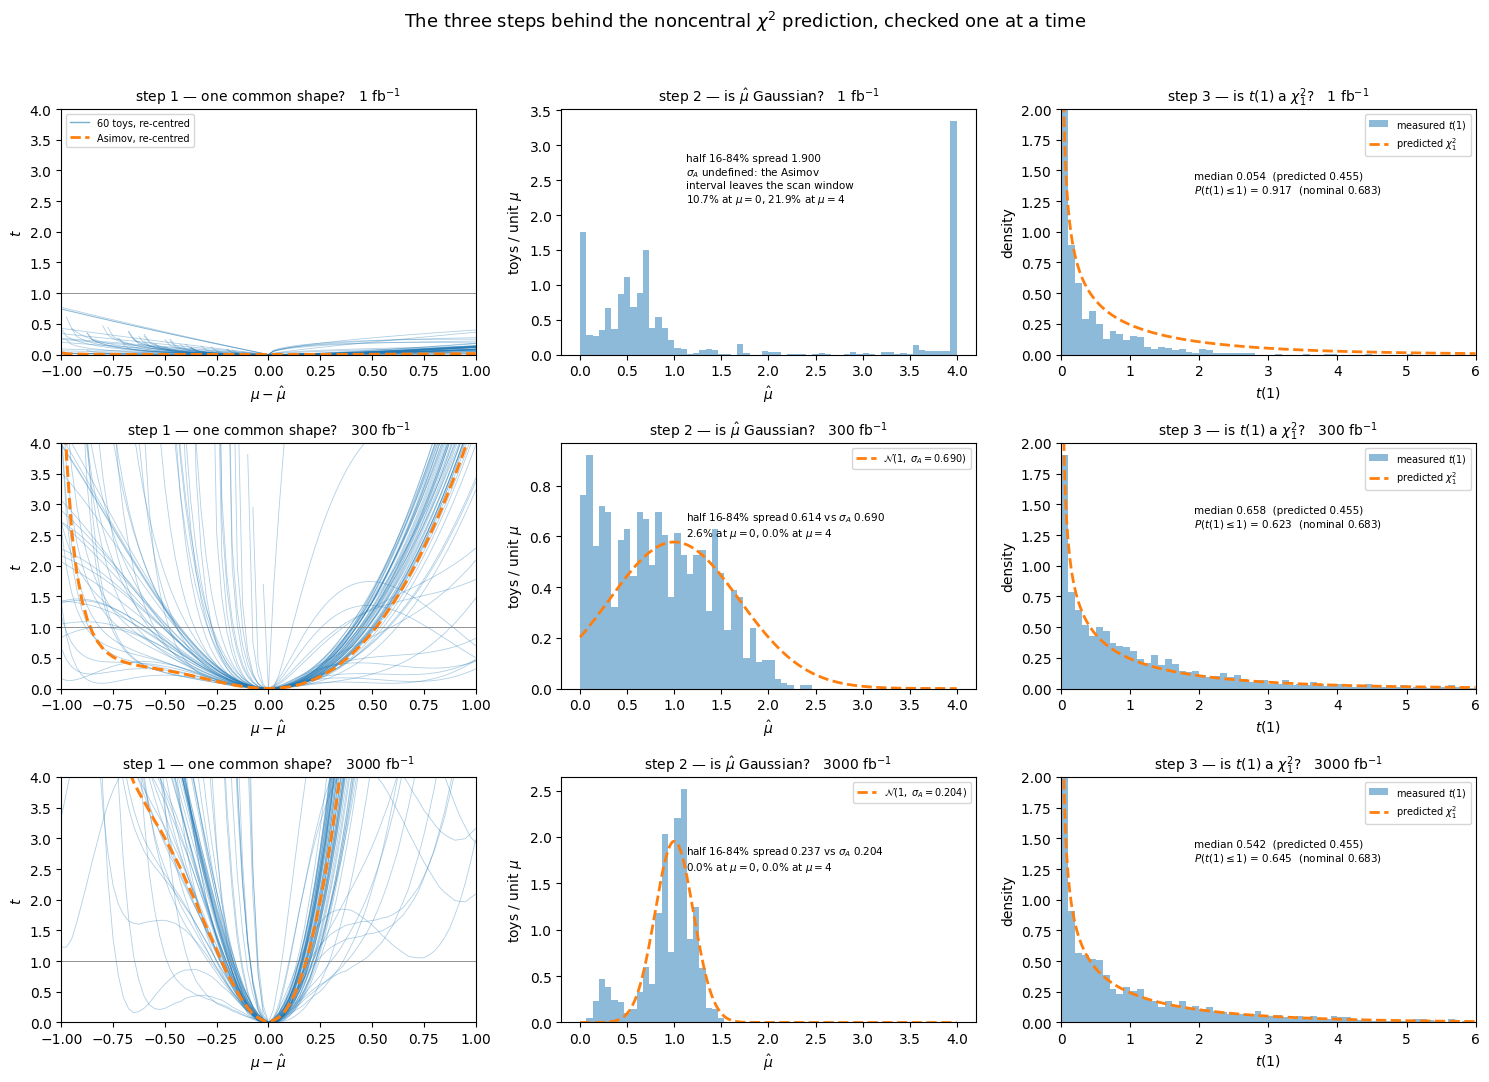

In [13]:
def chi2_1_density(t, lam=0.0):
    """Probability density of a noncentral chi-square with 1 degree of freedom.

    T = (Z + sqrt(lam))^2 with Z standard normal, so this is the derivative of ncx2_cdf.
    It is used for drawing only; ncx2_cdf / ncx2_quantile in asimov_scan.py stay the
    single reference implementation, and the check below ties this density back to them.
    """
    t = np.asarray(t, dtype=np.float64)
    s, sl = np.sqrt(np.clip(t, 1e-300, None)), np.sqrt(np.clip(lam, 0.0, None))
    gauss = lambda x: np.exp(-0.5 * x ** 2) / np.sqrt(2 * np.pi)
    return (gauss(s - sl) + gauss(s + sl)) / (2 * s)


def recentre(t_curve, mu_hat, offsets, mu_grid):
    """t as a function of (mu - mu_hat); nan where the offset leaves the scan window."""
    x = offsets + mu_hat
    return np.where((x >= mu_grid[0]) & (x <= mu_grid[-1]), np.interp(x, mu_grid, t_curve), np.nan)


def sigma_asimov(t_asim, mu_grid):
    """Half the Asimov 68% interval width; nan when that interval leaves the window."""
    return crossing_interval(t_asim, mu_grid)[2] / 2.0


# the density must be the derivative of the CDF that asimov_scan.py provides
_t, _h = np.array([0.3, 1.0, 2.5, 5.0]), 1e-4
for _lam in (0.0, 1.4, 5.0):
    _numeric = (ncx2_cdf(_t + _h, _lam) - ncx2_cdf(_t - _h, _lam)) / (2 * _h)
    assert np.allclose(chi2_1_density(_t, _lam), _numeric, rtol=1e-5), _lam

ROWS = [1, 300, 3000]
offs = np.linspace(-1.0, 1.0, 161)
rng_show = np.random.default_rng(0)
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for row, L in enumerate(ROWS):
    t_toys, mu_hats = t_curves(scans[L]['nll_toys'], mu)
    t_asim, _ = t_curves(scans[L]['nll_asimov'], mu)
    sigA = sigma_asimov(t_asim, mu)
    at_lo, at_hi = np.mean(mu_hats <= mu[1]), np.mean(mu_hats >= mu[-2])

    # ---- step 1: re-centred on each curve's own minimum, is there one common shape? ----
    ax = axes[row, 0]
    for j in rng_show.choice(t_toys.shape[1], 60, replace=False):
        ax.plot(offs, recentre(t_toys[:, j], mu_hats[j], offs, mu), '-', color='C0', lw=0.6, alpha=0.35)
    ax.plot(offs, recentre(t_asim, 1.0, offs, mu), '--', color='C1', lw=2.2)
    ax.axhline(1.0, color='grey', lw=0.6)
    ax.set_ylim(0, 4); ax.set_xlim(-1, 1)
    ax.set_xlabel('$\\mu - \\hat\\mu$'); ax.set_ylabel('$t$')
    ax.set_title(f'step 1 — one common shape?   {L:g} fb$^{{-1}}$', fontsize=10)
    if row == 0:
        ax.plot([], [], '-', color='C0', lw=1, alpha=0.6, label='60 toys, re-centred')
        ax.plot([], [], '--', color='C1', lw=2, label='Asimov, re-centred')
        ax.legend(fontsize=7, loc='upper left')

    # ---- step 2: is the best fit Gaussian about 1 with the Asimov width? ----
    ax = axes[row, 1]
    ax.hist(mu_hats, bins=np.linspace(0, 4, 61), density=True, color='C0', alpha=0.5)
    lo84, hi84 = np.quantile(mu_hats, [0.16, 0.84])
    spread = (hi84 - lo84) / 2
    if np.isfinite(sigA):
        xs = np.linspace(0, 4, 400)
        ax.plot(xs, np.exp(-0.5 * ((xs - 1) / sigA) ** 2) / (sigA * np.sqrt(2 * np.pi)),
                '--', color='C1', lw=2, label=f'$\\mathcal{{N}}(1,\\ \\sigma_A={sigA:.3f})$')
        ax.legend(fontsize=7, loc='upper right')
        note = f'half 16-84% spread {spread:.3f} vs $\\sigma_A$ {sigA:.3f}'
    else:
        note = (f'half 16-84% spread {spread:.3f}\n$\\sigma_A$ undefined: the Asimov'
                '\ninterval leaves the scan window')
    ax.text(0.30, 0.62, note + f'\n{at_lo:.1%} at $\\mu=0$, {at_hi:.1%} at $\\mu=4$',
            transform=ax.transAxes, fontsize=7.5)
    ax.set_xlabel('$\\hat\\mu$'); ax.set_ylabel('toys / unit $\\mu$')
    ax.set_title(f'step 2 — is $\\hat\\mu$ Gaussian?   {L:g} fb$^{{-1}}$', fontsize=10)

    # ---- step 3: at mu = 1 the prediction is a central chi-square, whatever the model ----
    ax = axes[row, 2]
    t_at_1 = t_toys[I_MU1, :]
    ax.hist(t_at_1, bins=np.linspace(0, 6, 61), density=True, color='C0', alpha=0.5,
            label='measured $t(1)$')
    xs = np.linspace(1e-3, 6, 600)
    ax.plot(xs, chi2_1_density(xs, 0.0), '--', color='C1', lw=2, label='predicted $\\chi^2_1$')
    ax.set_ylim(0, 2.0); ax.set_xlim(0, 6)
    ax.text(0.32, 0.66, f'median {np.median(t_at_1):.3f}  (predicted 0.455)\n'
                        f'$P(t(1)\\leq 1)$ = {np.mean(t_at_1 <= 1):.3f}  (nominal 0.683)',
            transform=ax.transAxes, fontsize=7.5)
    ax.set_xlabel('$t(1)$'); ax.set_ylabel('density')
    ax.set_title(f'step 3 — is $t(1)$ a $\\chi^2_1$?   {L:g} fb$^{{-1}}$', fontsize=10)
    ax.legend(fontsize=7, loc='upper right')
fig.suptitle('The three steps behind the noncentral $\\chi^2$ prediction, checked one at a time',
             fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

## 4. Self-test of the comparison machinery on ideal likelihoods

Before the comparison is applied to the histogram scans, it is worth checking it on a case where
the three steps of §2 hold by construction rather than approximately. The curves used here are
therefore not fitted to anything: they are parabolas $t(\mu) = (\mu - \hat\mu)^2/\sigma^2$ whose
minima are drawn from $\hat\mu \sim \mathcal{N}(\mu_{\rm true}, \sigma)$, which is step 1 and step
2 imposed exactly. Any disagreement seen here would be a fault of the comparison code, not of the
physics, and the three checks below would catch it.

1. the median of $t(\mu_{\rm true})$ across toys is $0.455$, the median of a central $\chi^2_1$;
2. the width of the median-of-$t$ curve, measured from its own minimum at threshold 1, is
   $1.185\times$ the Asimov width;
3. the measured quantile curves lie on the predicted noncentral $\chi^2_1$ quantile curves at
   every $\mu$, the first two checks being simply two points of this identity.

Both constants are the ones computed in §2 rather than independent numbers, so this cell closes
the loop between the derivation and the code that will be used on the data.

median of t at mu_true : measured 0.456, predicted 0.455
median-curve width / Asimov width : measured 1.177, predicted 1.185


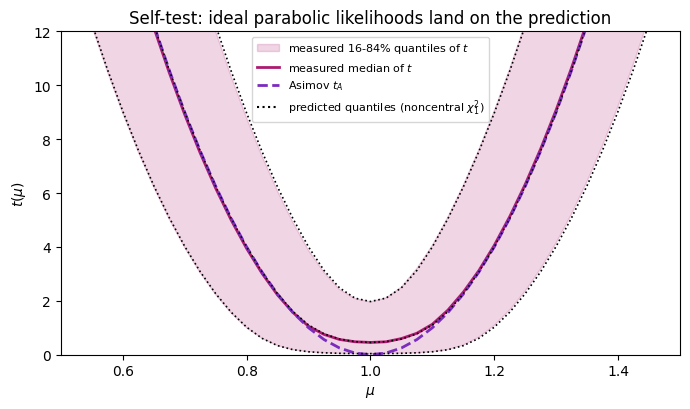

In [14]:
rng = np.random.default_rng(1)
sigma, n_ideal = 0.10, 4000
mu_hat_ideal = rng.normal(1.0, sigma, n_ideal)
t_ideal = ((mu[:, None] - mu_hat_ideal[None, :]) / sigma) ** 2
t_asim_ideal = ((mu - 1.0) / sigma) ** 2

q16, q50, q84 = toy_quantiles(t_ideal)
p16, p50, p84 = predicted_quantiles(t_asim_ideal)

med_at_truth = q50[I_MU1]
_, _, w_med = crossing_interval(q50 - q50.min(), mu)
_, _, w_a = crossing_interval(t_asim_ideal, mu)
print(f"median of t at mu_true : measured {med_at_truth:.3f}, predicted {ncx2_quantile(0.5, 0.0):.3f}")
print(f"median-curve width / Asimov width : measured {w_med / w_a:.3f}, predicted 1.185")
assert abs(med_at_truth - 0.455) < 0.03 and abs(w_med / w_a - 1.185) < 0.02

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.fill_between(mu, q16, q84, alpha=0.18, color=PINK, label='measured 16-84% quantiles of $t$')
ax.plot(mu, q50, '-', color=PINK, lw=2, label='measured median of $t$')
ax.plot(mu, t_asim_ideal, '--', color=PURPLE, lw=2, label='Asimov $t_A$')
for p, ls in [(p16, ':'), (p50, ':'), (p84, ':')]:
    ax.plot(mu, p, ls, color='k', lw=1.2)
ax.plot([], [], ':', color='k', label='predicted quantiles (noncentral $\\chi^2_1$)')
ax.set_xlim(0.5, 1.5); ax.set_ylim(0, 12)
ax.set_xlabel('$\\mu$'); ax.set_ylabel('$t(\\mu)$')
ax.set_title('Self-test: ideal parabolic likelihoods land on the prediction')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. The measurement

With the machinery checked, the same comparison is now applied to the histogram scans, one panel
per luminosity. Each panel carries three ingredients, and it is worth being explicit about which
line style is which, since two of the three are broken lines:

* **pink solid, with shading** — the *measured* 16%/50%/84% quantiles of $t(\mu)$ across the 2000
  toys;
* **black dotted**, three curves per panel — the *predicted* 16%/50%/84% quantiles, that is, the
  corresponding quantiles of the noncentral $\chi^2_1$ distribution with $\Lambda = t_A(\mu)$;
* **purple dashed** — the Asimov curve $t_A(\mu)$ itself.

Two grey horizontal lines mark the thresholds at which an interval is read off: $t = 1$ and
$t = 4$, the values a $\chi^2$ with one degree of freedom takes at 68.3% and 95.4% probability,
conventionally called $1\sigma$ and $2\sigma$.

**How to read one panel.** The comparison is pink solid against black dotted: the property holds
where the measured curves lie on the predicted ones. The purple dashed curve is *not* a target. As
established in §2 it sits below the pink median by construction, by $0.455$ at $\mu = 1$, and a
panel in which pink met purple would be evidence of a mistake rather than of agreement; it is
drawn only because it is the input from which the black curves are computed, entering as the
noncentrality parameter. The 1 fb$^{-1}$ panel shows this arrangement at its clearest: there
$t_A \approx 0$ across the whole window, so $\Lambda \approx 0$ and the three predicted curves
flatten onto the constant quantiles of a *central* $\chi^2_1$, roughly $0.04$, $0.45$ and $1.97$.

The percentage quoted in each corner is the fraction of toys whose best fit sits at the $\mu = 0$
boundary; where it is appreciable, the free-movement assumption behind the prediction is violated
outright and any deviation in that panel should be read in that light. The upper edge of the scan
window matters as well at the lowest luminosities, and §8 reports both edges together.

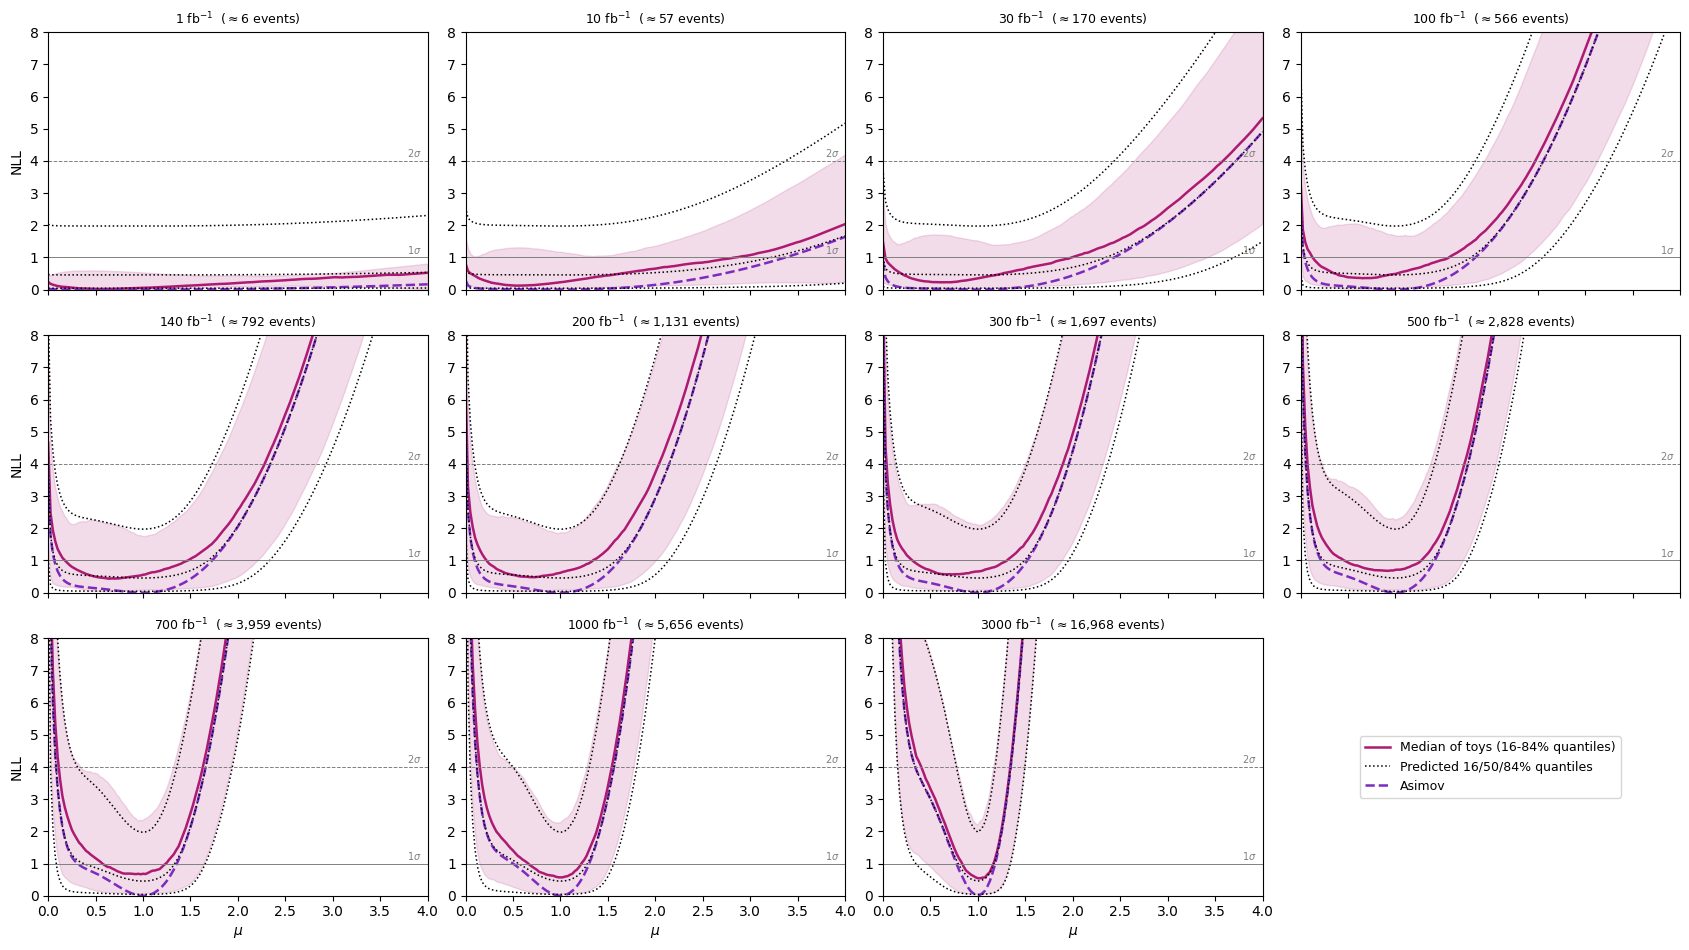

In [20]:
def panel(ax, L, ymax=8.0):
    r = scans[L]
    t_toys, mu_hats = t_curves(r['nll_toys'], mu)
    t_asim, _ = t_curves(r['nll_asimov'], mu)
    q16, q50, q84 = toy_quantiles(t_toys)
    p16, p50, p84 = predicted_quantiles(t_asim)
    ax.fill_between(mu, q16, q84, alpha=0.15, color=PINK)
    ax.plot(mu, q50, '-', color=PINK, lw=1.8)
    ax.plot(mu, t_asim, '--', color=PURPLE, lw=1.8)
    for p in (p16, p50, p84):
        ax.plot(mu, p, ':', color='k', lw=1.1)
    # 1 sigma and 2 sigma thresholds for one degree of freedom
    for lev, lab, ls in ((1.0, '1\\sigma', '-'), (4.0, '2\\sigma', '--')):
        ax.axhline(lev, color='grey', lw=0.7, ls=ls)
        ax.text(3.94, lev + 0.12, f'${lab}$', fontsize=7, color='grey', ha='right')
    frac0 = float(np.mean(mu_hats <= mu[1]))
    # ax.text(0.03, 0.92, f'{np.mean(mu_hats <= mu[1]):.0%} of toys at $\\hat\\mu=0$',
    #         transform=ax.transAxes, fontsize=7.5)
    ax.set_ylim(0, ymax); ax.set_xlim(mu[0], mu[-1])
    ax.set_title(f'{L:g} fb$^{{-1}}$  ($\\approx${5.656*L:,.0f} events)', fontsize=9)
    return t_toys, t_asim, mu_hats

fig, axes = plt.subplots(3, 4, figsize=(17, 10), sharex=True)
per_lumi = {}
for ax, L in zip(axes.ravel(), LUMIS):
    per_lumi[L] = panel(ax, L)
axes.ravel()[-1].axis('off')
handles = [plt.Line2D([], [], color=PINK, lw=1.8,
                      label='Median of toys (16-84% quantiles)'),
           plt.Line2D([], [], color='k', ls=':', lw=1.1,
                      label='Predicted 16/50/84% quantiles'),
           plt.Line2D([], [], color=PURPLE, ls='--', lw=1.8,
                      label='Asimov')]
        #    plt.Line2D([], [], color='grey', lw=0.7,
        #               label='grey: the $1\\sigma$ and $2\\sigma$ thresholds, $t = 1$ and $t = 4$')]
axes.ravel()[-1].legend(handles=handles, loc='center', fontsize=9)
for ax in axes[-1, :]: ax.set_xlabel('$\\mu$')
for ax in axes[:, 0]: ax.set_ylabel('NLL')
#fig.suptitle('Histogram analysis: measured vs predicted quantiles of $t(\\mu)$, toys at $\\mu_{true}=1$', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

## 6. Summary table

The panels above are read off by eye; this table puts numbers on them, one row per luminosity.
Two of the columns, `r_med` and `t(1): med/pred`, are the two points of the §2 identity singled
out in the self-test, and are the ones to look at first.

| column | definition |
|---|---|
| `mu_A` | best fit of the Asimov dataset; must be 1.000 for a correctly implemented likelihood, since the Asimov dataset has no fluctuation to pull the fit away |
| `med(mu_t)`, `q25`, `q75` | median and quartiles of the 2000 per-toy best fits $\hat\mu$ |
| `at0` | fraction of toys with $\hat\mu = 0$ (within one grid step) |
| `w_A` | width of the Asimov 68% interval, where $t_A$ crosses 1; `nan` means the interval is not contained in the scan window |
| `med(w_t)` | median of the per-toy 68% interval widths, the number an experiment would quote; `open` counts toys whose interval is not contained in the window |
| `r_med` | width of the median-of-$t$ curve, measured from its own minimum, divided by the Asimov width, with a bootstrap-over-toys error. Its large-sample expectation is **1.185**, not 1 — see §2 |
| `t(1): med/pred` | measured median of $t(1)$ across toys against its predicted value 0.455. Since $\Lambda = t_A(1) = 0$, this is the one column whose prediction is model-independent |
| `cover` | fraction of toys whose 68% interval contains $\mu = 1$, equivalently with $t(1) \le 1$; nominal 0.683 |
| `max\|m-p\|` | largest deviation over the grid between the measured and predicted median curves. This is an absolute difference in units of $t$, so it grows with luminosity simply because $t$ itself grows; it flags where to look rather than measuring how bad the disagreement is |

In [16]:
rows = []
hdr = (f"{'L':>5} {'mu_A':>6} {'med(mu_t)':>9} {'q25':>6} {'q75':>6} {'at0':>5} "
       f"{'w_A':>6} {'med(w_t)':>8} {'open':>5} {'r_med':>13} {'t(1)med':>8} {'pred':>6} "
       f"{'cover':>6} {'max|m-p|':>9}")
print(hdr); print('-' * len(hdr))
summary = {}
for L in LUMIS:
    t_toys, t_asim, mu_hats = per_lumi[L]
    _, _, w_a = crossing_interval(t_asim, mu)
    widths = np.array([crossing_interval(t_toys[:, i], mu)[2] for i in range(t_toys.shape[1])])
    n_open = int(np.isnan(widths).sum())
    q16, q50, q84 = toy_quantiles(t_toys)
    p50 = predicted_quantiles(t_asim, qs=(0.5,))[0]
    ratio, err = bootstrap_quantile_width_ratio(t_toys, t_asim, mu)
    cover = float(np.mean(t_toys[I_MU1, :] <= 1.0))
    row = dict(L=L, mu_A=float(mu[np.argmin(t_asim)]), med_mu=float(np.median(mu_hats)),
               q25=float(np.quantile(mu_hats, 0.25)), q75=float(np.quantile(mu_hats, 0.75)),
               at0=float(np.mean(mu_hats <= mu[1])), w_A=w_a,
               med_w=float(np.nanmedian(widths)), n_open=n_open, ratio=ratio, ratio_err=err,
               t1_med=float(q50[I_MU1]), t1_pred=float(p50[I_MU1]), cover=cover,
               maxdev=float(np.nanmax(np.abs(q50 - p50))))
    summary[L] = row
    print(f"{L:>5g} {row['mu_A']:>6.3f} {row['med_mu']:>9.3f} {row['q25']:>6.2f} {row['q75']:>6.2f} "
          f"{row['at0']:>5.1%} {row['w_A']:>6.3f} {row['med_w']:>8.3f} {row['n_open']:>5d} "
          f"{row['ratio']:>6.3f}+-{row['ratio_err']:<5.3f} {row['t1_med']:>8.3f} {row['t1_pred']:>6.3f} "
          f"{row['cover']:>6.3f} {row['maxdev']:>9.3f}")

    L   mu_A med(mu_t)    q25    q75   at0    w_A med(w_t)  open         r_med  t(1)med   pred  cover  max|m-p|
---------------------------------------------------------------------------------------------------------------


/tmp/ipykernel_2269318/2294071237.py:19: RuntimeWarning: All-NaN slice encountered
  med_w=float(np.nanmedian(widths)), n_open=n_open, ratio=ratio, ratio_err=err,


    1  1.000     0.675   0.40   3.48 10.7%    nan      nan  2000    nan+-nan      0.054  0.455  0.917     0.437
   10  1.000     0.650   0.30   1.88 14.8%    nan    2.043  1436    nan+-nan      0.229  0.455  0.816     0.365
   30  1.000     0.650   0.25   1.55 13.7%    nan    1.837   808    nan+-nan      0.349  0.455  0.768     0.471
  100  1.000     0.675   0.28   1.30  8.8%  1.803    1.408   249  0.936+-0.016    0.486  0.455  0.709     0.579
  140  1.000     0.700   0.30   1.33  6.3%  1.663    1.241   158  0.962+-0.018    0.556  0.455  0.670     0.675
  200  1.000     0.725   0.33   1.25  4.6%  1.526    1.079    86  0.922+-0.013    0.618  0.455  0.649     1.211
  300  1.000     0.788   0.35   1.25  2.6%  1.380    0.929    30  0.972+-0.018    0.658  0.455  0.623     0.836
  500  1.000     0.850   0.43   1.23  0.9%  1.197    0.761     5  1.015+-0.016    0.710  0.455  0.599     0.871
  700  1.000     0.900   0.50   1.20  0.4%  1.047    0.676     0  1.022+-0.016    0.682  0.455  0.595   

## 7. Summary versus luminosity

The four quantities most directly tied to the §2 identity are now plotted against luminosity, so
that the approach to the large-sample limit can be seen rather than inferred from the table. The
first two panels carry the constants derived in §2 as dotted reference lines; the third is the
coverage of the interval an experiment would quote; the fourth is the fraction of toys sitting at
the $\mu = 0$ boundary, which sets how far the prediction can be trusted at the low-luminosity
end.

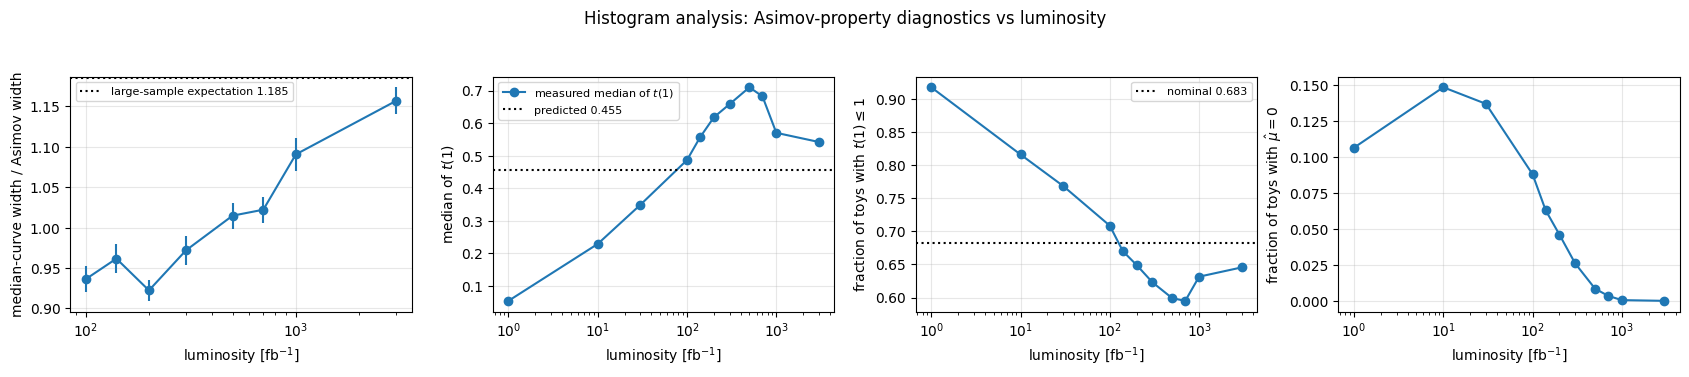

In [17]:
Ls = np.array(LUMIS, dtype=float)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
ax = axes[0]
r = np.array([summary[L]['ratio'] for L in LUMIS]); e = np.array([summary[L]['ratio_err'] for L in LUMIS])
ax.errorbar(Ls, r, yerr=e, fmt='o-', color='C0')
ax.axhline(1.185, color='k', ls=':', label='large-sample expectation 1.185')
ax.set_ylabel('median-curve width / Asimov width'); ax.legend(fontsize=8)
ax = axes[1]
ax.plot(Ls, [summary[L]['t1_med'] for L in LUMIS], 'o-', color='C0', label='measured median of $t(1)$')
ax.axhline(0.455, color='k', ls=':', label='predicted 0.455')
ax.set_ylabel('median of $t(1)$'); ax.legend(fontsize=8)
ax = axes[2]
ax.plot(Ls, [summary[L]['cover'] for L in LUMIS], 'o-', color='C0')
ax.axhline(0.683, color='k', ls=':', label='nominal 0.683')
ax.set_ylabel('fraction of toys with $t(1) \\leq 1$'); ax.legend(fontsize=8)
ax = axes[3]
ax.plot(Ls, [summary[L]['at0'] for L in LUMIS], 'o-', color='C0')
ax.set_ylabel('fraction of toys with $\\hat\\mu = 0$')
for ax in axes:
    ax.set_xscale('log'); ax.set_xlabel('luminosity [fb$^{-1}$]'); ax.grid(alpha=0.3)
fig.suptitle('Histogram analysis: Asimov-property diagnostics vs luminosity', fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.93]); plt.show()

## 8. Which of the three assumptions fails, and where

Section 3 examined the three steps at three luminosities; this section follows the two that can be
reduced to a single number across the whole range, so that the approach to the large-sample limit
can be attributed to one step or the other rather than left as a combined effect.

* **Step 1** is summarised by the median per-toy 68% interval width divided by the Asimov width.
  Were the toy curves the Asimov curve shifted, the two widths would agree and the ratio would sit
  at 1; a ratio below 1 says the typical toy curve is steeper than the Asimov curve, and therefore
  that a toy would quote a tighter interval than the Asimov dataset predicts.
* **Step 2** is summarised by the spread of $\hat\mu$ across toys divided by $\sigma_A$, again
  using half the 16%-84% interval as the spread so that outlying toys do not dominate. This too
  should approach 1.

Both ratios need the Asimov 68% interval to be contained in the scan window, which it is not below
100 fb$^{-1}$; the third panel shows why, by counting the toys whose best fit is pinned at either
end of the window. That count is worth reading alongside the `at0` column of §6, which reports
only the lower end: at 1 fb$^{-1}$ a further fifth of the toys sit at the *upper* edge, so the
lower-edge fraction alone understates by roughly a factor of three how many fits are unconstrained.
Below 100 fb$^{-1}$ the likelihood is too flat for a 68% interval to close inside $\mu \in [0,4]$
at all, and the question of whether the asymptotic prediction holds is not so much answered as
inapplicable.

**Why both ratios sit below 1, and why the pile-up is two-sided.** These two failures are not
independent accidents of sample size but consequences of the point at which the toys are
generated, a mechanism characterised in the audit of 2026-07-11 and written up in
`rate_degeneracy.ipynb` as the *interference rate-fold*. With $\sigma_{\rm sig} = +0.310$ fb,
$\sigma_{\rm int} = -0.606$ fb and $\sigma_{\rm bkg} = 5.953$ fb, the expected yield
$\nu(\mu) = \mu\sigma_{\rm sig} + \sqrt{\mu}\,\sigma_{\rm int} + \sigma_{\rm bkg}$ has a minimum at
$\mu^* = 0.957$, so that at the generation point
$d\nu/d\mu|_1 = \sigma_{\rm sig} + \sigma_{\rm int}/2 = 0.0067$ fb per unit $\mu$, about one part
in a thousand of the yield. That notebook puts the rate share of the Fisher information at
$\mu = 1$ at $3.8\times10^{-6}$ out of $8.5\times10^{-3}$ per fb$^{-1}$, which is zero to the
precision quoted: near the generation point all sensitivity comes from the shape of the
$m_{4\ell}$ distribution, and the rate contributes only in the far tails. The same reference
records that the fold drives inflation of $t$, a bias in $\hat\mu$ and a coverage failure, which
are the three deviations tabulated in §6.

The two-sided pile-up follows from the same picture, since a rate that is not monotonic cannot
order $\mu$: on this sample $\nu$ takes the values 5.964, 5.657 and 5.985 events per fb$^{-1}$ at
$\mu = 0$, 1 and 4, so $\mu = 0$ and $\mu \approx 3.5$ predict the same yield, and a toy that
fluctuates upward in rate is pushed away from $\mu^*$ in either direction. This is what a
non-monotonic rate would predict rather than something separately established here; testing it
directly would need the per-toy event counts, which the stored scans do not carry.

/tmp/ipykernel_2269318/4034869138.py:7: RuntimeWarning: All-NaN slice encountered
  step1.append(np.nanmedian(widths) / w_a)          # is the toy curve shape the Asimov shape?


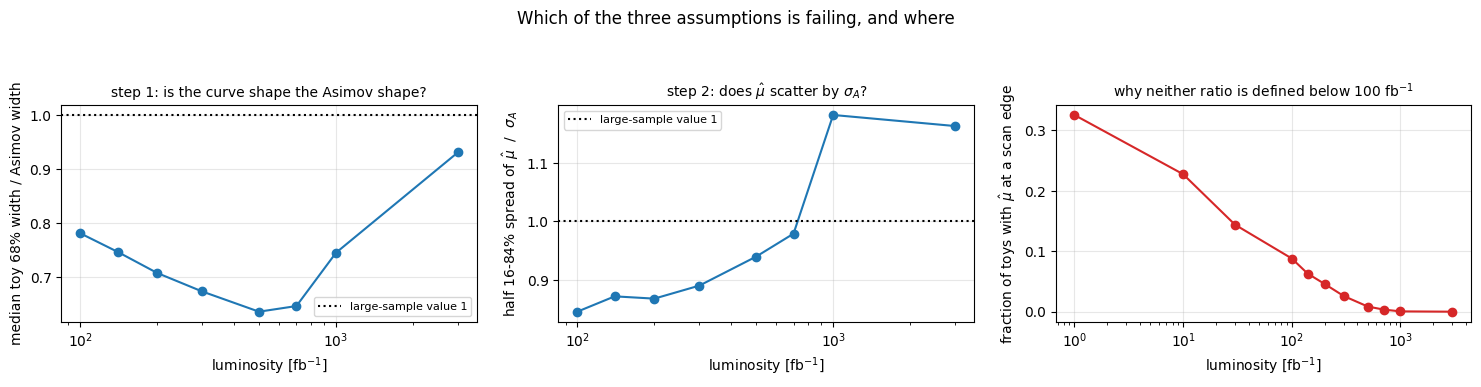

     L   step1   step2  at any edge
     1     nan     nan       32.6%
    10     nan     nan       22.8%
    30     nan     nan       14.4%
   100   0.781   0.846        8.8%
   140   0.746   0.872        6.3%
   200   0.707   0.868        4.6%
   300   0.673   0.890        2.6%
   500   0.635   0.940        0.9%
   700   0.646   0.979        0.4%
  1000   0.745   1.182        0.1%
  3000   0.931   1.163        0.0%


In [18]:
step1, step2, edge = [], [], []
for L in LUMIS:
    t_toys, t_asim, mu_hats = per_lumi[L]
    _, _, w_a = crossing_interval(t_asim, mu)
    widths = np.array([crossing_interval(t_toys[:, i], mu)[2] for i in range(t_toys.shape[1])])
    lo84, hi84 = np.quantile(mu_hats, [0.16, 0.84])
    step1.append(np.nanmedian(widths) / w_a)          # is the toy curve shape the Asimov shape?
    step2.append((hi84 - lo84) / w_a)                 # (hi-lo)/2 divided by w_a/2
    edge.append(float(np.mean((mu_hats <= mu[1]) | (mu_hats >= mu[-2]))))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
axes[0].plot(Ls, step1, 'o-', color='C0')
axes[0].set_ylabel('median toy 68% width / Asimov width')
axes[0].set_title('step 1: is the curve shape the Asimov shape?', fontsize=10)
axes[1].plot(Ls, step2, 'o-', color='C0')
axes[1].set_ylabel('half 16-84% spread of $\\hat\\mu$  /  $\\sigma_A$')
axes[1].set_title('step 2: does $\\hat\\mu$ scatter by $\\sigma_A$?', fontsize=10)
for ax in axes[:2]:
    ax.axhline(1.0, color='k', ls=':', label='large-sample value 1')
    ax.legend(fontsize=8)
axes[2].plot(Ls, edge, 'o-', color='C3')
axes[2].set_ylabel('fraction of toys with $\\hat\\mu$ at a scan edge')
axes[2].set_title('why neither ratio is defined below 100 fb$^{-1}$', fontsize=10)
for ax in axes:
    ax.set_xscale('log'); ax.set_xlabel('luminosity [fb$^{-1}$]'); ax.grid(alpha=0.3)
fig.suptitle('Which of the three assumptions is failing, and where', fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.92]); plt.show()

print(f"{'L':>6} {'step1':>7} {'step2':>7} {'at any edge':>12}")
for L, a, b, c in zip(LUMIS, step1, step2, edge):
    print(f"{L:>6g} {a:>7.3f} {b:>7.3f} {c:>11.1%}")

## 9. Comparison to Tae's original plots (diagnostic only)

Tae's slides overlay the **median of the raw $-2\ln L$ curves**, without the per-toy best-fit
subtraction that defines $t$, on the Asimov curve, after shifting the toy curves by one common
constant; his band, where present, is built from the raw curves too, so it can go negative. The
panels below reproduce that construction at every luminosity, rather than at the four of his
slide 6, and add for comparison the correctly-subtracted median of $t$ used in §5. Horizontal
lines mark the $1\sigma$ and $2\sigma$ thresholds, $t = 1$ and $t = 4$, which are the values a
$\chi^2$ with one degree of freedom takes at 68.3% and 95.4% probability.

**What the comparison shows.** The pink curve lies on the purple one at every luminosity, to
within roughly the line width, and the table below says the same in numbers: where both crossings
fall inside the scan window, the raw median reproduces the Asimov $1\sigma$ width to within 3.6%
and the $2\sigma$ width to within 1.8%. The green curve, which is the statistic §5 actually tests,
instead sits *above* the Asimov curve by the offset derived in §2 — asymptotically $0.455$ at
$\mu = 1$, and measured here as $0.49$ to $0.71$ from 100 fb$^{-1}$ upwards. Below that the offset
is smaller still, but so is everything else: the likelihood is too flat for the asymptotic picture
to apply at all, as §8 sets out.

This is worth stating plainly, because it explains why the original plots looked like a passing
test. Taking the median across toys at fixed $\mu$ of curves that differ only through their
observed counts returns, to a good approximation, the curve of the *typical* dataset, and the
typical dataset is essentially the Asimov dataset. Agreement in that convention is therefore close
to automatic and carries little information about the distribution of $t$. What makes the
comparison a test at all is the subtraction of each toy's own minimum: a different, non-linear
operation for every toy, which does not commute with taking the median, and which is what
introduces the predicted offset. Agreement with this construction is accordingly not a success
criterion of the redo; it is reproduced here only so that the two conventions can be seen side by
side.

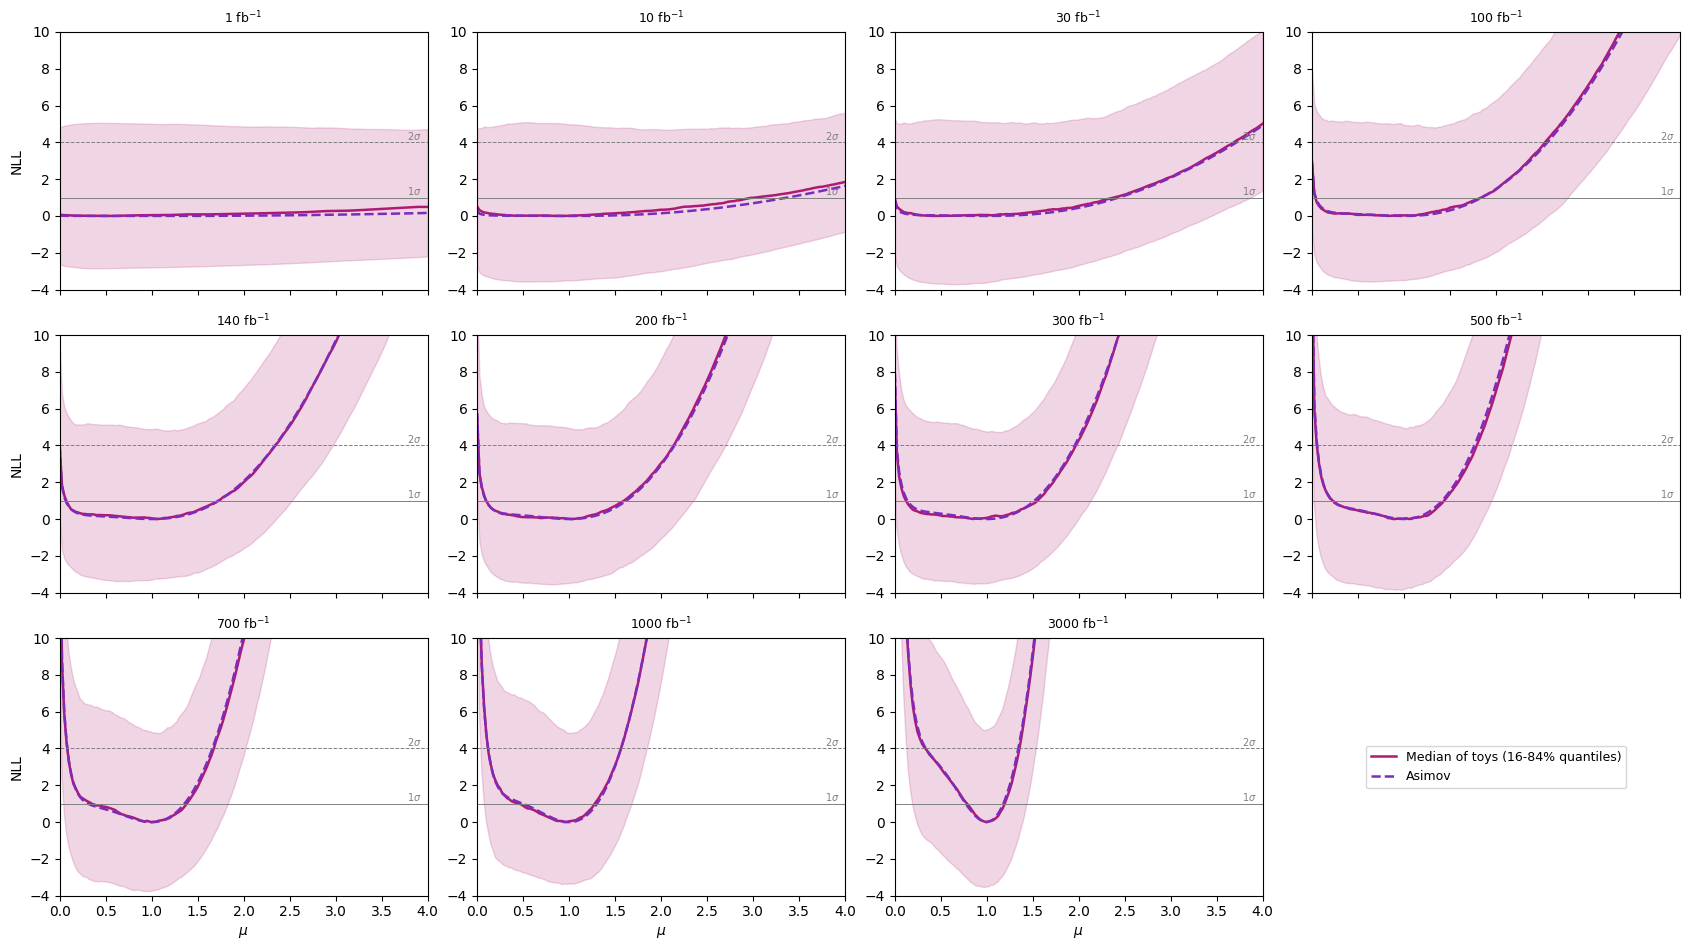

     L | Asimov 1sig   2sig | raw-median 1sig   2sig | t-median 1sig   2sig
---------------------------------------------------------------------------
     1 |         nan    nan |             nan    nan |           nan    nan
    10 |         nan    nan |             nan    nan |           nan    nan
    30 |         nan    nan |           2.381    nan |         2.210    nan
   100 |       1.803    nan |           1.805    nan |         1.688    nan
   140 |       1.663  2.341 |           1.656    nan |         1.599  2.343
   200 |       1.526  2.132 |           1.500  2.124 |         1.408  2.087
   300 |       1.380  1.934 |           1.430  1.949 |         1.342  1.936
   500 |       1.197  1.709 |           1.213  1.738 |         1.215  1.729
   700 |       1.047  1.576 |           1.033  1.592 |         1.070  1.588
  1000 |       0.804  1.445 |           0.828  1.444 |         0.876  1.446
  3000 |       0.408  1.005 |           0.409  1.023 |         0.472  1.028

interval wi

In [24]:
fig, axes = plt.subplots(3, 4, figsize=(17, 10), sharex=True)
tae_rows = []
for ax, L in zip(axes.ravel(), LUMIS):
    T = scans[L]['nll_toys']
    off = np.median(T, axis=1).min()                 # one common shift, Tae's convention
    lo, med, hi = np.quantile(T - off, [0.16, 0.50, 0.84], axis=1)
    da = scans[L]['nll_asimov'] - scans[L]['nll_asimov'].min()
    t_toys, _ = t_curves(T, mu)
    q50 = toy_quantiles(t_toys, qs=(0.5,))[0]        # the statistic used in section 5

    ax.fill_between(mu, lo, hi, alpha=0.18, color=PINK)
    ax.plot(mu, med, '-', color=PINK, lw=1.8)
    ax.plot(mu, da, '--', color=PURPLE, lw=1.8)
    #ax.plot(mu, q50, '-', color='cyan', lw=1.3)
    for lev, lab, ls in ((1.0, '1\\sigma', '-'), (4.0, '2\\sigma', '--')):
        ax.axhline(lev, color='grey', lw=0.7, ls=ls)
        ax.text(3.94, lev + 0.15, f'${lab}$', fontsize=7, color='grey', ha='right')
    ax.set_ylim(-4, 10); ax.set_xlim(mu[0], mu[-1])
    ax.set_title(f'{L:g} fb$^{{-1}}$', fontsize=9)

    row = [L]
    for curve in (da, med - med.min(), q50 - q50.min()):
        row += [crossing_interval(curve, mu, 1.0)[2], crossing_interval(curve, mu, 4.0)[2]]
    tae_rows.append(row)

axes.ravel()[-1].axis('off')
handles = [plt.Line2D([], [], color=PINK, lw=1.8,
                      label="Median of toys (16-84% quantiles)"),
        #    plt.Line2D([], [], color='C2', lw=1.3,
        #               label='Asimov'),
           plt.Line2D([], [], color=PURPLE, ls='--', lw=1.8, label='Asimov')]
axes.ravel()[-1].legend(handles=handles, loc='center', fontsize=9)
for ax in axes[-1, :]: ax.set_xlabel('$\\mu$')
for ax in axes[:, 0]: ax.set_ylabel('NLL')
#fig.suptitle("Tae's plotting convention at every luminosity, against the statistic used in §5", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

hdr = (f"{'L':>6} | {'Asimov 1sig':>11} {'2sig':>6} | {'raw-median 1sig':>15} {'2sig':>6} "
       f"| {'t-median 1sig':>13} {'2sig':>6}")
print(hdr); print('-' * len(hdr))
for r in tae_rows:
    print(f"{r[0]:>6g} | {r[1]:>11.3f} {r[2]:>6.3f} | {r[3]:>15.3f} {r[4]:>6.3f} "
          f"| {r[5]:>13.3f} {r[6]:>6.3f}")
print("\ninterval widths at the 1sigma (t=1) and 2sigma (t=4) thresholds, each curve measured\n"
      "from its own minimum; nan = the crossing lies outside the scan window")

## 10. Errata in the original study (histogram-relevant rows)

The following were found while redoing the analysis. Each row carries its evidence and the
consequence measured here; agreement with results built on these errors was not a target of this
redo.

| # | error | evidence | consequence measured here |
|---|---|---|---|
| 1 | median taken over raw $-2\ln L$ curves without per-toy best-fit subtraction | `asimov-aymptotics-check/notebooks/compare_median_vs_asimov.ipynb`, cell 3 | the overlaid curves differ by each toy's random offset $-2\ln L(\hat\mu)$; §9 and §5 show the two conventions side by side |
| 2 | `torch.median` returns the lower middle element at an even number of toys | same cell | at 200 toys shifts the median curve by up to one inter-toy spacing; `np.quantile` used throughout here |
| 3 | all toys drawn from a single seeded call | `notebooks/hist/fit_asimov_and_toys.ipynb`, toy cell (`random_state=42`) | no independent-stream guarantee across toys; redo uses one stream per toy (`SeedSequence.spawn`) |
| 4 | slide 6 titled "NSBI" while showing the histogram analysis | `docs/presentations/asimov_vs_medtoys_test_statistic_studies.pdf`, p. 6 | labelling only |
| 5 | overlaying median-of-$t$ (or median-of-raw) directly on the Asimov curve as the property test | slides 6-7 | ill-defined test: the median of $t$ carries a predicted offset of $0.455$ at $\mu_{\rm true}$ and a predicted width factor of $1.185$, both derived in §2, so the two curves cannot coincide even in a perfectly asymptotic analysis; the redo compares measured against predicted quantiles instead |

(NSBI-specific errata — the missing event-count term and the checkpoint-selection rule — are in
`nsbi_reproduction.ipynb`.)

## 11. Reproduce

```bash
cd /project/atlas/Users/mfernand/SBI_shortcomings
SIF=asimov-aymptotics-check/ml4fp-sbi-tutorial.sif
B="apptainer exec --bind /project/atlas/Users --pwd $PWD --env PYTHONNOUSERSITE=1 $SIF"

# the scans this notebook reads (CPU, ~15 min)
$B python scripts/asimov_scan.py --analysis hist \
  --lumis 1 10 30 100 140 200 300 500 700 1000 3000 \
  --n-toys 2000 --mu-max 4 --mu-points 161 --seed 42 --out output/asimov_scan/hist

# closure against the pre-redo outputs (Tae's exact configuration)
$B python scripts/asimov_scan.py --analysis hist --lumis 1 10 100 1000 \
  --n-toys 200 --mu-max 4 --mu-points 101 --legacy-seed-block --out output/asimov_scan/closure

# execute this notebook headlessly
$B bash -c "PYTHONPATH=$PWD/output/pyextra python -m nbconvert --to notebook --execute \
  --ExecutePreprocessor.kernel_name=python3 --ExecutePreprocessor.timeout=1800 \
  --inplace notebooks/histogram_reproduction.ipynb"
```

Two details in the last command are needed rather than optional, and both were found on
2026-07-21 when the earlier version of it failed. `PYTHONPATH` must be absolute, because the
kernel is started with the notebook's own directory as its working directory and a relative path
would no longer resolve; and `kernel_name` must be given, because the kernel this notebook is
saved against (`sbi-notebooks`, the LCG_109_swan stack used interactively) is not registered
inside the container. Passing `kernel_name` on the command line does not alter the kernel recorded
in the notebook, so interactive runs are unaffected.

Closure result (2026-07-16): the legacy-configuration run reproduces the pre-redo tensors to
float32 rounding (largest absolute difference $4\times10^{-3}$ on curves of magnitude $10^4$-$10^5$,
i.e. $\sim 2\times10^{-7}$ relative) and the published summary numbers exactly
(width ratios $0.990$ and $1.052$ at 100/1000 fb$^{-1}$, Asimov $\hat\mu = 1.000$ everywhere,
open intervals at 1-10 fb$^{-1}$).